# 作業一｜統計分析（Ch14–18）

| 項目 | 內容 |
|---|---|
| 配分 | 100 分 |
| 形式 | 每組 2～3 人，共 10 組 |
| 分工 | **三人組**：A 第一、二題；B 第三、四題；C 第五題。<br>**二人組**：A 第一、二、四題；B 第三、五題。<br>第六題由全組共同完成。 |
| 負責方式 | 每位組員負責所分配大題的全部計算、文字回答與口頭報告；第六題由全組共同彙整。 |
| 繳交 | 執行完成的 `.ipynb`，檔名 `作業一_第X組.ipynb` |

## 共同限制

1. 樣本期間 2019-01-02 至 2025-12-31，個股與大盤（`^TWII`）取共同交易日。
2. 報酬率一律為**對數報酬**，單位 %。
3. 年化以 245 個交易日計；無風險利率為年化 1.5%。
4. 顯著水準 5%（題目另有指定除外）；所有隨機程序使用 `np.random.default_rng(42)`。
5. 只可使用 `numpy`、`pandas`、`scipy`、`statsmodels`、`matplotlib`。
6. 標示「**手算**」者須依公式自行實作，現成函式只能用來比對結果。
7. 文字題每小題至多 3 句，且必須引用你算出的數字。

In [10]:
# 填寫組別與組員
我的組別 = 9      # 1~10

組員 = {              # (姓名, 學號)
    'A': ('M154020027', '蔡凱安'),
    'B': ('M154020042', '李嘉欣'),
    'C': ('M154020051', '涂耀恩'),                     # 三人組才填 ('姓名', '學號')；兩人組維持 None
}

---
## 資料（直接執行）

| 組別 | 股票 | 代碼 | 特性 | 組別 | 股票 | 代碼 | 特性 |
|---|---|---|---|---|---|---|---|
| 第 1 組 | 台積電 | `2330.TW` | 權值王、高波動 | 第 2 組 | 聯發科 | `2454.TW` | IC 設計 |
| 第 3 組 | 鴻海 | `2317.TW` | 代工龍頭 | 第 4 組 | 中華電 | `2412.TW` | 電信、低波動 |
| 第 5 組 | 廣達 | `2382.TW` | AI 伺服器 | 第 6 組 | 台塑 | `1301.TW` | 塑化 |
| 第 7 組 | 統一 | `1216.TW` | 食品、防禦型 | 第 8 組 | 國泰金 | `2882.TW` | 金控 |
| 第 9 組 | 長榮 | `2603.TW` | 航運、暴漲暴跌 | 第 10 組 | 和泰車 | `2207.TW` | 汽車 |

In [11]:
!pip install -q yfinance

In [2]:
import pandas as pd

import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
import warnings
warnings.filterwarnings('ignore')


def 設定中文字型():
    from matplotlib import font_manager
    for f in ['Noto Sans CJK TC', 'Noto Sans TC', 'PingFang TC',
              'Heiti TC', 'Microsoft JhengHei']:
        if f in {x.name for x in font_manager.fontManager.ttflist}:
            plt.rcParams['font.sans-serif'] = [f]
            plt.rcParams['axes.unicode_minus'] = False
            return f
    print('⚠ 找不到中文字型，圖上的中文會變方框（不影響分數）')


設定中文字型()
print('✅ 環境就緒')

✅ 環境就緒


In [9]:
# ⚙ 這一格直接執行，不用改。
# 功能：抓 Yahoo Finance 資料；如果 Yahoo 當掉，自動改用內嵌的備援資料。
import base64, gzip, io
import pandas as pd

_備援B64 = "..."


def _讀備援():
    原始 = gzip.decompress(base64.b64decode(_備援B64))
    df = pd.read_csv(io.BytesIO(原始), index_col=0, parse_dates=True)
    return df


def 安全下載(代碼, 起始=None, 結束=None):
    """回傳單一代碼的收盤價 Series。Yahoo 失敗時自動用備援資料。"""
    try:
        import yfinance as yf
        df = yf.download(代碼, start=起始, end=結束, auto_adjust=True,
                         progress=False)
        收 = df['Close']
        if hasattr(收, 'columns'):
            收 = 收.squeeze()
        收 = 收.dropna()
        if len(收) > 100:
            print(f'✅ 從 Yahoo 抓到 {代碼}：{len(收)} 筆，'
                  f'{收.index.min().date()} ~ {收.index.max().date()}')
            return 收
        raise ValueError('資料太少')
    except Exception as e:
        print(f'⚠ Yahoo 抓取失敗（{type(e).__name__}），改用內嵌備援資料')
        備 = _讀備援()
        if 代碼 not in 備.columns:
            raise KeyError(f'備援資料沒有 {代碼}，可用：{list(備.columns)}')
        收 = 備[代碼].dropna()
        if 起始:
            收 = 收[收.index >= 起始]
        if 結束:
            收 = 收[收.index < 結束]
        print(f'✅ 備援資料 {代碼}：{len(收)} 筆，'
              f'{收.index.min().date()} ~ {收.index.max().date()}')
        return 收

In [12]:
分組表 = {
    1: ('2330.TW', '台積電'),
    2: ('2454.TW', '聯發科'),
    3: ('2317.TW', '鴻海'),
    4: ('2412.TW', '中華電'),
    5: ('2382.TW', '廣達'),
    6: ('1301.TW', '台塑'),
    7: ('1216.TW', '統一'),
    8: ('2882.TW', '國泰金'),
    9: ('2603.TW', '長榮'),
    10: ('2207.TW', '和泰車'),
}

我的組別 = 9

我的代碼, 我的名稱 = 分組表[我的組別]
股價 = 安全下載(我的代碼, '2019-01-01', '2026-01-01')
大盤 = 安全下載('^TWII', '2019-01-01', '2026-01-01')

print(f'第 {我的組別} 組：{我的名稱}（{我的代碼}）')

✅ 從 Yahoo 抓到 2603.TW：1698 筆，2019-01-02 ~ 2025-12-31
✅ 從 Yahoo 抓到 ^TWII：1699 筆，2019-01-02 ~ 2025-12-31
第 9 組：長榮（2603.TW）


---
# 第一題｜描述統計與常態性（12 分）　負責人：A

**1-1（4 分）** 建立個股與大盤的日對數報酬 `r`、`m`（依共同限制 1、2）。輸出一張比較表：平均數、中位數、標準差、偏態、超額峰態、最小值、最大值、年化平均、年化波動度。

In [13]:
# 第一題 1-1：描述統計與常態性
import numpy as np
import pandas as pd

# 1. 計算日對數報酬率
r = np.log(股價 / 股價.shift(1))
m = np.log(大盤 / 大盤.shift(1))

# 2. 合併個股與大盤，依共同交易日期對齊
報酬率 = pd.concat([r, m], axis=1)
報酬率.columns = ['長榮', '大盤']
報酬率 = 報酬率.dropna()

# 3. 建立描述統計比較表
統計表 = pd.DataFrame({
    '平均數': 報酬率.mean(),
    '中位數': 報酬率.median(),
    '標準差': 報酬率.std(),
    '偏態': 報酬率.skew(),
    '超額峰態': 報酬率.kurt(),
    '最小值': 報酬率.min(),
    '最大值': 報酬率.max(),
    '年化平均': 報酬率.mean() * 252,
    '年化波動度': 報酬率.std() * np.sqrt(252)
})

# 4. 轉成比較表
統計表 = 統計表.T

print("第9組：長榮（2603.TW）與台灣大盤描述統計比較")
display(統計表.round(4))

第9組：長榮（2603.TW）與台灣大盤描述統計比較


,長榮,大盤
平均數,0.0017,0.0007
中位數,0.0000,0.0010
標準差,0.0309,0.0118
偏態,-0.2339,-0.7713
超額峰態,3.0537,9.2030
最小值,-0.1784,-0.1020
最大值,0.0953,0.0884
年化平均,0.4240,0.1654
年化波動度,0.4907,0.1879


**1-2（4 分）手算** 偏態與超額峰態，各算有偏（母體動差）與偏誤校正兩種版本，並與 `scipy.stats.skew`／`kurtosis`（`bias=True`、`bias=False`）及 pandas 的 `.skew()`／`.kurt()` 比對，絕對誤差須小於 1e-10。

In [14]:
import numpy as np
import pandas as pd
from scipy.stats import skew, kurtosis

def 手算統計(x):
    x = np.asarray(x, dtype=float)
    n = len(x)

    d = x - np.mean(x)
    m2 = np.mean(d**2)
    m3 = np.mean(d**3)
    m4 = np.mean(d**4)

    # 母體動差版
    s_true = m3 / m2**1.5
    k_true = m4 / m2**2 - 3

    # 偏誤校正版
    s_false = np.sqrt(n * (n - 1)) / (n - 2) * s_true
    k_false = ((n**2 - 1) * k_true + 6 * (n - 1)) / ((n - 2) * (n - 3))

    return s_true, s_false, k_true, k_false

結果 = []

for 名稱 in ['長榮', '大盤']:
    x = 報酬率[名稱].dropna().to_numpy()

    s_t, s_f, k_t, k_f = 手算統計(x)

    結果.append({
        '資料': 名稱,
        '手算偏態 bias=True': s_t,
        'SciPy 偏態 bias=True': skew(x, bias=True),
        '手算偏態 bias=False': s_f,
        'SciPy 偏態 bias=False': skew(x, bias=False),
        'pandas 偏態': pd.Series(x).skew(),
        '手算峰態 bias=True': k_t,
        'SciPy 峰態 bias=True': kurtosis(x, fisher=True, bias=True),
        '手算峰態 bias=False': k_f,
        'SciPy 峰態 bias=False': kurtosis(x, fisher=True, bias=False),
        'pandas 峰態': pd.Series(x).kurt()
    })

比較表 = pd.DataFrame(結果).set_index('資料')

display(比較表.round(6))

,手算偏態 bias=True,SciPy 偏態 bias=True,手算偏態 bias=False,SciPy 偏態 bias=False,pandas 偏態,手算峰態 bias=True,SciPy 峰態 bias=True,手算峰態 bias=False,SciPy 峰態 bias=False,pandas 峰態
資料,,,,,,,,,,
長榮,-0.233720,-0.233720,-0.233926,-0.233926,-0.233926,3.041160,3.041160,3.053684,3.053684,3.053684
大盤,-0.770612,-0.770612,-0.771294,-0.771294,-0.771294,9.172362,9.172362,9.202989,9.202989,9.202989


**1-3（4 分）手算** Jarque–Bera 統計量與 p 值，個股與大盤各一，並與 `stats.jarque_bera` 比對。

In [15]:

# 第一題 1-3：手算 Jarque-Bera 統計量與 p 值

import numpy as np
import pandas as pd
from scipy.stats import jarque_bera, chi2

結果_JB = []

for 名稱 in ['長榮', '大盤']:
    x = 報酬率[名稱].dropna().to_numpy()
    n = len(x)

    # 1. 手算偏態與超額峰態（母體動差版）
    平均 = np.mean(x)
    d = x - 平均

    m2 = np.mean(d**2)
    m3 = np.mean(d**3)
    m4 = np.mean(d**4)

    S = m3 / (m2 ** 1.5)
    K = m4 / (m2 ** 2) - 3

    # 2. 手算 JB 統計量
    JB = n / 6 * (S**2 + K**2 / 4)

    # 3. 計算 p 值
    p_value = chi2.sf(JB, df=2)

    # 4. SciPy 驗證
    scipy_result = jarque_bera(x)

    結果_JB.append({
        '資料': 名稱,
        '樣本數': n,
        '手算 JB': JB,
        'SciPy JB': scipy_result.statistic,
        '手算 p 值': p_value,
        'SciPy p 值': scipy_result.pvalue,
        'JB 絕對誤差': abs(JB - scipy_result.statistic),
        'p 值絕對誤差': abs(p_value - scipy_result.pvalue)
    })

JB比較表 = pd.DataFrame(結果_JB).set_index('資料')

display(JB比較表)

# 5. 常態性檢定結論（顯著水準 0.05）
for 名稱 in ['長榮', '大盤']:
    p = JB比較表.loc[名稱, '手算 p 值']

    if p < 0.05:
        print(f'{名稱}：p < 0.05，拒絕常態分配假設')
    else:
        print(f'{名稱}：p >= 0.05，無法拒絕常態分配假設')


,樣本數,手算 JB,SciPy JB,手算 p 值,SciPy p 值,JB 絕對誤差,p 值絕對誤差
資料,,,,,,,
長榮,1697,669.406768,669.406768,4.366840e-146,0.0,3.410605e-13,4.366840e-146
大盤,1697,6116.807802,6116.807802,0.000000e+00,0.0,0.000000e+00,0.000000e+00


長榮：p < 0.05，拒絕常態分配假設
大盤：p < 0.05，拒絕常態分配假設


**文字題（併入 1-2、1-3）**

- (a) 個股的報酬與風險相對大盤如何？光看這張表能不能說它「比較好」？
- (b) 有偏與校正版本在你的樣本數下差多少？什麼情況下這個差異才重要？
- (c) JB 檢定的結論是什麼？這對第二、三、五題會用到的哪些方法構成威脅？

**答：**



(a)從統計結果可以看到，長榮的日平均報酬率是 0.17%，比大盤的 0.07% 高，年化平均報酬率也是長榮比較高，代表這段期間長榮的平均報酬表現比較好。

不過，長榮的波動也比較大，年化波動度達到 49.07%，大約是大盤的 2.6 倍，而且長榮最大的單日跌幅也比大盤高，表示投資長榮需要承擔比較大的風險。

所以我認為不能只看這張表，就說長榮一定比較好。雖然它的平均報酬比較高，但風險也比較大，還是要考慮投資人能承受多少風險，以及承擔這些風險是否值得，才能判斷哪個投資標的比較適合。

(b)本次分析的樣本數為 1,697 筆，屬於相對充足的樣本，因此有偏版本（bias=True）與偏誤校正版（bias=False）的結果差異不大。

以長榮為例，兩種版本的偏態相差約 0.000207，超額峰態相差約 0.012524；大盤的偏態相差約 0.000682，超額峰態相差約 0.030627。可以看到，校正後的數值雖然略有變化，但不會改變長榮與大盤皆呈現負偏態及厚尾分布的結論。

不過，如果樣本數較少，偏誤校正的影響就可能比較明顯，尤其是超額峰態，因為極端值容易影響高階動差。當研究需要精確比較不同樣本的偏態、峰態，或判斷尾部風險時，這些差異就值得特別注意。

(c)從 JB 檢定的結果可以看到，長榮的 JB 統計量約為 669.41，大盤約為 6116.81，兩者的 p 值都遠小於 0.05，所以我們可以拒絕常態分配的假設，代表長榮和大盤的報酬率都不符合常態分配。這也跟前面分析出來的負偏態和厚尾現象一致。

這個結果可能會影響後面第二、三、五題的分析，因為有些統計方法會假設資料符合常態分配。如果直接套用這些方法，可能會低估股票出現極端漲跌的風險，也可能影響部分統計檢定的準確性。

因此，後續分析時需要特別注意常態分配的假設是否適用，必要時可以搭配 Bootstrap 或歷史模擬等方法來確認結果，讓分析更可靠。

---
# 第二題｜尾部風險（18 分）　負責人：A

**2-1（5 分）** 繪製 `r` 的直方圖（密度），疊上以樣本平均與標準差建立的常態密度，以及以 `stats.t.fit` 擬合的 t 分配密度；標題註明擬合的自由度。

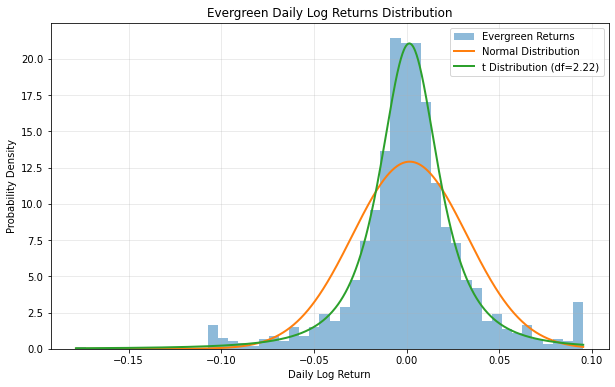

樣本平均數：0.001683
樣本標準差：0.030909
t 分配自由度 df：2.2181
t 分配位置參數 loc：0.001500
t 分配尺度參數 scale：0.016977


In [16]:

# 第二題 2-1：長榮日對數報酬率分布

import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

# 1. 使用第一題計算好的日對數報酬率 r
data = r.dropna().to_numpy()

# 2. 常態分配參數
mu = np.mean(data)
sigma = np.std(data, ddof=1)

# 3. 使用 scipy 擬合 t 分配
df, loc, scale = stats.t.fit(data)

# 4. 建立繪圖範圍
x = np.linspace(data.min(), data.max(), 1000)

# 5. 繪製直方圖（密度）
plt.figure(figsize=(10, 6))
plt.hist(data, bins=50, density=True,
         alpha=0.5, label='Evergreen Returns')

# 6. 疊上常態分配曲線
plt.plot(x, stats.norm.pdf(x, mu, sigma),
         linewidth=2, label='Normal Distribution')

# 7. 疊上 t 分配曲線
plt.plot(x, stats.t.pdf(x, df, loc, scale),
         linewidth=2,
         label=f't Distribution (df={df:.2f})')

# 8. 圖表設定
plt.title('Evergreen Daily Log Returns Distribution')
plt.xlabel('Daily Log Return')
plt.ylabel('Probability Density')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

# 顯示擬合參數
print(f'樣本平均數：{mu:.6f}')
print(f'樣本標準差：{sigma:.6f}')
print(f't 分配自由度 df：{df:.4f}')
print(f't 分配位置參數 loc：{loc:.6f}')
print(f't 分配尺度參數 scale：{scale:.6f}')


**2-2（6 分）** 計算 95% 與 99% 的一日 VaR 與 ES（預期短缺），以**損失的正數（%）**表示，三種方法：常態、2-1 擬合的 t 分配、歷史模擬。常態與 t 的 ES 須用封閉解**手算**。輸出一張 3 方法 × 4 指標的表。

In [17]:

# 第二題 2-2：計算 VaR 與 ES

import numpy as np
import pandas as pd
from scipy import stats

# 取得長榮每日對數報酬率
data = r.dropna().to_numpy()
n = len(data)

# 常態分配參數（與 2-1 一致）
mu = np.mean(data)
sigma = np.std(data, ddof=1)

# t 分配擬合（與 2-1 一致）
df, loc, scale = stats.t.fit(data)

# 信心水準
levels = [0.95, 0.99]

結果 = []

# 方法一：常態分配
normal_result = {'方法': '常態分配'}

for level in levels:
    alpha = 1 - level
    z = stats.norm.ppf(alpha)

    # VaR：損失取正數
    var = -(mu + sigma * z)

    # ES：常態分配左尾條件期望
    es = -mu + sigma * stats.norm.pdf(z) / alpha

    normal_result[f'{int(level*100)}% VaR'] = var * 100
    normal_result[f'{int(level*100)}% ES'] = es * 100

結果.append(normal_result)

# 方法二：擬合 t 分配
t_result = {'方法': 't 分配'}

for level in levels:
    alpha = 1 - level
    q = stats.t.ppf(alpha, df)

    # t 分配 VaR
    var = -(loc + scale * q)

    # t 分配 ES（閉合公式）
    es = -loc + scale * (
        (df + q**2) / (df - 1)
    ) * stats.t.pdf(q, df) / alpha

    t_result[f'{int(level*100)}% VaR'] = var * 100
    t_result[f'{int(level*100)}% ES'] = es * 100

結果.append(t_result)

# 方法三：歷史模擬
historical_result = {'方法': '歷史模擬'}

for level in levels:
    alpha = 1 - level

    # 歷史報酬率左尾分位數
    q = np.quantile(data, alpha)

    # VaR
    var = -q

    # ES：歷史左尾平均損失
    es = -np.mean(data[data <= q])

    historical_result[f'{int(level*100)}% VaR'] = var * 100
    historical_result[f'{int(level*100)}% ES'] = es * 100

結果.append(historical_result)

# 整理成 3 × 4 比較表
風險比較表 = pd.DataFrame(結果).set_index('方法')

風險比較表 = 風險比較表[
    ['95% VaR', '95% ES', '99% VaR', '99% ES']
]

print('第9組：長榮（2603.TW）單日 VaR 與 ES 比較（單位：%）')
display(風險比較表.round(4))


第9組：長榮（2603.TW）單日 VaR 與 ES 比較（單位：%）


,95% VaR,95% ES,99% VaR,99% ES
方法,,,,
常態分配,4.9158,6.2073,7.0222,8.0696
t 分配,4.4904,8.8567,10.2151,18.9871
歷史模擬,4.8608,7.7376,10.1081,10.8521


**2-3（7 分）** 回測 99% VaR：以前 750 個交易日為滾動視窗，逐日估計下一日的常態 VaR 與歷史 VaR（不得使用當日及未來資料）。計算兩者的違約次數，並**手算** Kupiec POF 概似比檢定（統計量、p 值）。

In [18]:

# 第二題 2-3：99% VaR 回測與 Kupiec POF 檢定
# 第9組：長榮（2603.TW）

import numpy as np
import pandas as pd
from scipy import stats
from scipy.special import xlogy

# 1. 準備日對數報酬率
data = r.dropna().sort_index()

window = 750
alpha = 0.01

# 2. 計算滾動視窗的平均數與標準差
rolling_mu = data.rolling(window).mean()
rolling_sigma = data.rolling(window).std(ddof=1)

# 3. 常態 VaR（使用前750日，不含當日）
z = stats.norm.ppf(alpha)

normal_var = -(
    rolling_mu.shift(1) +
    z * rolling_sigma.shift(1)
)

# 4. 歷史模擬 VaR（使用前750日，不含當日）
historical_var = -(
    data.rolling(window)
    .quantile(alpha)
    .shift(1)
)

# 5. 建立回測資料表
backtest = pd.DataFrame({
    '實際報酬率': data,
    '常態VaR': normal_var,
    '歷史VaR': historical_var
}).dropna()

# 6. 轉為損失（正數代表損失）
backtest['實際損失'] = -backtest['實際報酬率']

# 7. 判斷是否違約（實際損失 > VaR）
backtest['常態違約'] = (
    backtest['實際損失'] > backtest['常態VaR']
)

backtest['歷史違約'] = (
    backtest['實際損失'] > backtest['歷史VaR']
)

# 8. 手算 Kupiec POF 檢定
def kupiec_pof(exceptions, alpha=0.01):
    n = len(exceptions)
    x = int(np.sum(exceptions))
    p_hat = x / n

    # 對數概似比統計量
    lr = 2 * (
        xlogy(x, p_hat / alpha) +
        xlogy(n - x, (1 - p_hat) / (1 - alpha))
    )

    # 自由度1的卡方分配
    p_value = stats.chi2.sf(lr, df=1)

    return n, x, p_hat, lr, p_value

# 9. 分別計算兩種方法的檢定結果
results = []

for method, column in [
    ('滾動常態VaR', '常態違約'),
    ('歷史模擬VaR', '歷史違約')
]:
    n, x, p_hat, lr, p = kupiec_pof(
        backtest[column].to_numpy(), alpha
    )

    results.append({
        '方法': method,
        '回測天數': n,
        '預期違約次數': n * alpha,
        '實際違約次數': x,
        '實際違約率': p_hat,
        'Kupiec LR統計量': lr,
        'p值': p,
        '5%顯著水準結論': (
            '拒絕H0' if p < 0.05 else '不拒絕H0'
        )
    })

# 10. 顯示結果
回測結果 = pd.DataFrame(results).set_index('方法')

print('第9組：長榮 99% VaR 回測結果')
display(回測結果.round(6))

print('\n最近5筆回測資料（百分比）')
display(
    (backtest[
        ['實際報酬率', '實際損失', '常態VaR', '歷史VaR']
    ].tail() * 100).round(4)
)


第9組：長榮 99% VaR 回測結果


,回測天數,預期違約次數,實際違約次數,實際違約率,Kupiec LR統計量,p值,5%顯著水準結論
方法,,,,,,,
滾動常態VaR,947,9.47,11,0.011616,0.237358,0.626121,不拒絕H0
歷史模擬VaR,947,9.47,4,0.004224,4.077176,0.043466,拒絕H0



最近5筆回測資料（百分比）


,實際報酬率,實際損失,常態VaR,歷史VaR
Date,,,,
2025-12-24,1.3351,-1.3351,5.3532,7.1787
2025-12-26,1.3175,-1.3175,5.3518,7.1787
2025-12-29,-0.2621,0.2621,5.3440,7.1787
2025-12-30,0.2621,-0.2621,5.3387,7.1787
2025-12-31,-0.5249,0.5249,5.3387,7.1787


**文字題（併入 2-2、2-3）**

- (a) 95% 與 99% 下，常態法相對歷史法是高估還是低估風險？為何兩個信心水準的方向可能不同？
- (b) 哪一種 VaR 通過 Kupiec 檢定？Kupiec 檢定沒有檢查到什麼？

**答：**



(a)在 95% 信心水準下，常態法的 VaR 是 4.92%，比歷史法的 4.86% 高，所以常態法稍微高估風險。

但在 99% 信心水準下，常態法的 VaR 是 7.02%，比歷史法的 10.11% 低，反而低估了風險。

這是因為 99% 更重視極端虧損的情況，而長榮的報酬率有厚尾現象，代表極端漲跌比常態分配預期的更容易發生，所以常態法在 99% 時可能會低估風險。

(b)從結果來看，滾動常態 VaR 的 p 值是 0.6261，大於 0.05，所以通過 Kupiec 檢定；歷史模擬 VaR 的 p 值是 0.0435，小於 0.05，因此沒有通過。

不過，Kupiec 檢定只會檢查違約次數是否符合預期，不會檢查違約是不是集中在某段時間，也不會看超過 VaR 時實際虧損有多大。

所以即使滾動常態 VaR 通過檢定，也不代表它的風險預測一定完全準確。

---
# 第三題｜推論統計（17 分）　負責人：B

**3-1（5 分）** 檢定 H₀：個股平均日報酬 = 0。報告 t 統計量、p 值、95% t 信賴區間；另以 bootstrap（B = 10,000，百分位法）建立平均數的 95% 信賴區間，與 t 區間並列比較。

In [19]:

# 第三題 3-1：t 檢定與 Bootstrap 信賴區間
# 第9組：長榮（2603.TW）

import numpy as np
import pandas as pd
from scipy import stats

# 1. 取得長榮日對數報酬率
data = r.dropna().to_numpy()
n = len(data)

# 2. 計算樣本平均數與標準差
mean = np.mean(data)
std = np.std(data, ddof=1)
se = std / np.sqrt(n)

# 3. 單一樣本 t 檢定 H0: 平均報酬 = 0
t_stat, p_value = stats.ttest_1samp(data, popmean=0)

# 4. 計算 t 分配 95% 信賴區間
t_critical = stats.t.ppf(0.975, df=n-1)

t_ci_lower = mean - t_critical * se
t_ci_upper = mean + t_critical * se

# 5. Bootstrap 重複抽樣 10,000 次
B = 10000
rng = np.random.default_rng(42)

bootstrap_means = np.empty(B)

for i in range(B):
    sample = rng.choice(data, size=n, replace=True)
    bootstrap_means[i] = np.mean(sample)

# 6. Bootstrap 百分位法 95% 信賴區間
boot_ci_lower, boot_ci_upper = np.percentile(
    bootstrap_means, [2.5, 97.5]
)

# 7. 整理結果
print('第9組：長榮（2603.TW）平均日報酬檢定')
print(f'樣本數：{n}')
print(f'平均日對數報酬率：{mean*100:.4f}%')
print(f't 統計量：{t_stat:.6f}')
print(f'p 值：{p_value:.6f}')

print('\n95% 信賴區間比較（單位：%）')

結果表 = pd.DataFrame({
    '方法': ['t 信賴區間', 'Bootstrap 信賴區間'],
    '下限 (%)': [t_ci_lower*100, boot_ci_lower*100],
    '上限 (%)': [t_ci_upper*100, boot_ci_upper*100]
})

display(結果表.round(4))

# 8. 檢定結論
if p_value < 0.05:
    print('結論：拒絕 H0，平均日報酬率與 0 有顯著差異')
else:
    print('結論：不拒絕 H0，沒有足夠證據認為平均日報酬率與 0 有顯著差異')


第9組：長榮（2603.TW）平均日報酬檢定
樣本數：1697
平均日對數報酬率：0.1683%
t 統計量：2.242424
p 值：0.025063

95% 信賴區間比較（單位：%）


,方法,下限 (%),上限 (%)
0,t 信賴區間,0.0211,0.3154
1,Bootstrap 信賴區間,0.0209,0.3185


結論：拒絕 H0，平均日報酬率與 0 有顯著差異


**3-2（6 分）** 令超額報酬 `d = r − m`。對「個股平均報酬 = 大盤平均報酬」分別做配對 t 檢定與 Welch t 檢定，報告兩者的 t 與 p，以及 `r`、`m` 的相關係數。另以樣本變異數與共變異數**手算**配對檢定的標準誤，驗證其與 `d` 的標準誤相同。

In [20]:

# 第三題 3-2：配對 t 檢定與 Welch t 檢定
# 第9組：長榮（2603.TW）

import numpy as np
import pandas as pd
from scipy import stats

# 1. 取出長榮與大盤的共同交易日報酬
data = pd.concat([r, m], axis=1).dropna()
data.columns = ['長榮', '大盤']

stock = data['長榮']
market = data['大盤']
d = stock - market

# 2. 配對 t 檢定
paired_t, paired_p = stats.ttest_rel(stock, market)

# 3. Welch t 檢定（不假設兩組變異數相等）
welch_t, welch_p = stats.ttest_ind(
    stock, market, equal_var=False
)

# 4. 計算相關係數
corr = stock.corr(market)

# 5. 手算配對 t 檢定標準誤
n = len(data)

var_r = stock.var(ddof=1)
var_m = market.var(ddof=1)
cov_rm = stock.cov(market)

# Var(r-m) = Var(r) + Var(m) - 2Cov(r,m)
var_d = var_r + var_m - 2 * cov_rm

se_paired = np.sqrt(var_d / n)

# 直接從 d 計算標準誤
se_d = d.std(ddof=1) / np.sqrt(n)

# 6. 顯示結果
print('第9組：長榮與大盤平均日報酬率比較')
print(f'共同交易日數：{n}')
print(f'長榮平均日報酬率：{stock.mean()*100:.4f}%')
print(f'大盤平均日報酬率：{market.mean()*100:.4f}%')
print(f'平均超額報酬率：{d.mean()*100:.4f}%')

結果表 = pd.DataFrame({
    '方法': ['配對 t 檢定', 'Welch t 檢定'],
    't 統計量': [paired_t, welch_t],
    'p 值': [paired_p, welch_p]
})

display(結果表.round(6))

print(f'\n長榮與大盤相關係數：{corr:.6f}')
print(f'手算配對標準誤：{se_paired:.12f}')
print(f'd 的標準誤：{se_d:.12f}')
print(f'兩者絕對誤差：{abs(se_paired-se_d):.12e}')

# 7. 判斷檢定結果
for name, p in [('配對 t 檢定', paired_p),
                ('Welch t 檢定', welch_p)]:
    if p < 0.05:
        print(f'{name}：拒絕 H0，平均報酬有顯著差異')
    else:
        print(f'{name}：不拒絕 H0，平均報酬沒有顯著差異的充分證據')


第9組：長榮與大盤平均日報酬率比較
共同交易日數：1697
長榮平均日報酬率：0.1683%
大盤平均日報酬率：0.0656%
平均超額報酬率：0.1026%


,方法,t 統計量,p 值
0,配對 t 檢定,1.486791,0.137256
1,Welch t 檢定,1.277349,0.201615



長榮與大盤相關係數：0.392140
手算配對標準誤：0.000690250265
d 的標準誤：0.000690250265
兩者絕對誤差：1.517883041480e-18
配對 t 檢定：不拒絕 H0，平均報酬沒有顯著差異的充分證據
Welch t 檢定：不拒絕 H0，平均報酬沒有顯著差異的充分證據


**3-3（6 分）** 以 `d` 的樣本平均與標準差作為真實效果，計算雙尾 5%、檢定力 80% 下配對 t 檢定所需的樣本天數，換算成年數。再求你目前樣本天數下的實際檢定力。

In [21]:

# 第三題 3-3：樣本數與檢定力分析
# 第9組：長榮（2603.TW）

import numpy as np
import pandas as pd
from statsmodels.stats.power import TTestPower

# 1. 取得長榮與大盤共同交易日的超額報酬
data = pd.concat([r, m], axis=1).dropna()
data.columns = ['長榮', '大盤']

d = data['長榮'] - data['大盤']

# 2. 使用 d 的樣本平均與標準差作為真實效果
n_current = len(d)
mean_d = d.mean()
std_d = d.std(ddof=1)

# 效果量 Cohen's d
effect_size = abs(mean_d / std_d)

# 3. 設定顯著水準與目標檢定力
alpha = 0.05
target_power = 0.80

power_analysis = TTestPower()

# 4. 計算達到80%檢定力所需樣本數
if effect_size > 0:
    n_required = power_analysis.solve_power(
        effect_size=effect_size,
        alpha=alpha,
        power=target_power,
        alternative='two-sided'
    )

    # 樣本數必須向上取整
    n_required = int(np.ceil(n_required))

    # 5. 計算目前樣本數下的實際檢定力
    current_power = power_analysis.power(
        effect_size=effect_size,
        nobs=n_current,
        alpha=alpha,
        alternative='two-sided'
    )
else:
    n_required = np.inf
    current_power = alpha

# 6. 換算交易年數（每年252交易日）
years_required = n_required / 252

# 7. 顯示結果
print('第9組：長榮相對大盤超額報酬之檢定力分析')
print(f'目前樣本數：{n_current}')
print(f'平均超額報酬率：{mean_d*100:.6f}%')
print(f'超額報酬標準差：{std_d*100:.6f}%')
print(f'效果量 Cohen d：{effect_size:.6f}')
print(f'所需樣本數：{n_required}')
print(f'約需交易年數：{years_required:.2f} 年')
print(f'目前樣本數的檢定力：{current_power*100:.2f}%')

# 8. 整理成比較表
結果表 = pd.DataFrame({
    '項目': [
        '目前樣本數',
        '效果量 Cohen d',
        '目標檢定力',
        '所需樣本數',
        '所需交易年數',
        '目前實際檢定力'
    ],
    '結果': [
        n_current,
        effect_size,
        target_power,
        n_required,
        years_required,
        current_power
    ]
})

display(結果表.round(4))


第9組：長榮相對大盤超額報酬之檢定力分析
目前樣本數：1697
平均超額報酬率：0.102626%
超額報酬標準差：2.843462%
效果量 Cohen d：0.036092
所需樣本數：6028
約需交易年數：23.92 年
目前樣本數的檢定力：31.80%


,項目,結果
0,目前樣本數,1697.0000
1,效果量 Cohen d,0.0361
2,目標檢定力,0.8000
3,所需樣本數,6028.0000
4,所需交易年數,23.9206
5,目前實際檢定力,0.3180


**文字題（併入 3-2、3-3）**

- (a) 配對與 Welch 的 p 值差多少？用相關係數與 3-2 的標準誤解釋；本題應採用哪一個？
(b) 若配對檢定不顯著，能否宣稱「個股與大盤表現相同」？用 3-3 的結果回答。

**答：**



(a)配對 t 檢定的 p 值是 0.1373，Welch t 檢定是 0.2016，兩者相差約 0.0644，都大於 0.05，表示目前沒有足夠證據認為長榮和大盤的平均報酬有明顯差異。

我認為這題應該使用配對 t 檢定，因為長榮和大盤是同一天的資料，而且相關係數為 0.3921，代表兩者有一定的正相關。配對檢定會考慮這個關係，所以標準誤比較小，也比較適合這題。

(b)不能直接說長榮和大盤的表現相同，因為檢定不顯著，只代表目前沒有足夠證據證明兩者有差異，不代表真的一樣。

從 3-3 的結果來看，目前有 1,697 筆資料，但檢定力只有 31.80%，低於目標的 80%。如果要達到 80% 的檢定力，估計需要 6,028 筆資料，大約 23.92 年。

所以目前可能是因為檢定力不足，才沒有發現顯著差異，不能因此認定長榮和大盤的平均報酬相同。

---
# 第四題｜變異數分析（13 分）　負責人：三人組 B／二人組 A

**4-1（5 分）** 以年份（2019–2025，共 7 組）為因子檢定個股平均日報酬是否相同：Levene 檢定（中位數中心）、古典單因子 ANOVA、Welch ANOVA、Kruskal–Wallis。並**手算** η² 與 ω²。

In [ ]:
# 作答

**4-2（4 分）** 以 Tukey HSD 做事後比較，列出 `reject=True` 的年份組合（若無，輸出「無」）。

In [ ]:
# 作答

**4-3（4 分）** 新增因子「大盤狀態」（`m > 0` 為上漲日，否則下跌日），以 `年 × 大盤狀態` 做含交互作用的雙因子 ANOVA（Type II），報告各效果的 F、p 與偏 η²。

In [ ]:
# 作答

**文字題（併入 4-1 ～ 4-3）**

- (a) 四種單因子檢定結論是否一致？Levene 的結果決定你應以哪一個為準？
- (b) η² 與 ω² 顯示年份的實質影響多大？
- (c) 交互作用項在財務上代表什麼？它顯著與否說明了什麼？

**答：**



---
# 第五題｜迴歸分析（30 分）　負責人：三人組 C／二人組 B

**5-1（8 分）** 以超額報酬估計 CAPM 市場模型 `r − r_f = α + β (m − r_f) + ε`（`r_f` 由年化 1.5% 換算為日對數報酬 %）。在三種標準誤下報告 α（日、年化）、β 的估計值、標準誤與 p 值：一般 OLS、HC3、Newey–West（`maxlags=5`）。並在 Newey–West 下檢定 H₀：β = 1。

In [ ]:
# 作答

**5-2（8 分）** 以 2022-01-01 為界檢定結構性改變：

1. **手算** Chow 檢定 F 值與 p 值（以全期、前期、後期三條迴歸的殘差平方和）。
2. 以虛擬變數與交互作用項估計同一模型，用一般 OLS 標準誤做聯合 F 檢定，驗證與 1. 的 F 相同。
3. 同一聯合檢定改用 Newey–West 標準誤再做一次，報告前後期的 α、β。

In [ ]:
# 作答

**5-3（7 分）** 對 5-1 模型做殘差診斷：殘差對配適值散佈圖、殘差 Q-Q 圖，Breusch–Pagan 檢定、Durbin–Watson 統計量、殘差 JB 檢定。

In [ ]:
# 作答

**5-4（7 分）手算** 以 250 個交易日滾動視窗，用共變異數／變異數計算滾動 β，並以最後一個視窗的 OLS 斜率驗證（誤差小於 1e-10）。繪製滾動 β 走勢，疊上全期 β 與 5-2 的前後期 β 水平線，並標出滾動 β 的最小值、最大值與其日期。

In [ ]:
# 作答

**文字題（併入 5-1 ～ 5-4）**

- (a) 三種標準誤下 α 的結論是否改變？依 5-3 的診斷，哪一種標準誤最適當？
- (b) β 是否顯著異於 1？這對「個股報酬較高」提供了什麼解釋？
- (c) 結構性改變是否成立？若成立，5-1 的全期 α、β 還能怎麼解讀？
- (d) 滾動 β 的走勢是否支持 5-2 的結論？以單一斷點切兩段的做法有什麼侷限？

**答：**



---
# 第六題｜結論（10 分）　全組

**6-1（4 分）** 將第一至五題的關鍵數字整理成一張表（至少含：年化平均與波動、超額峰態、99% 常態與歷史 VaR、Kupiec p 值、配對 t 的 p 值、所需年數、Welch ANOVA p 值、α 年化與 p 值、β、Chow p 值）。

In [ ]:
# 作答

**6-2（6 分）** 以不超過 5 句話回答：

1. 你的股票是否顯著贏過大盤？
2. 超額報酬較可能來自 α 還是 β？
3. 本作業中哪一個結論在更換方法或假設後改變了？這告訴你什麼？

**答：**